# 🎯 VCT Oddsmaker — Análisis Exploratorio de Datos (EDA)

**Predicción de probabilidades de victoria por mapa en el Valorant Champions Tour (2024–2026)**

*Aprendizaje de Máquina · Grupo C1 · Periodo 2026-2 · Primera entrega*

Repositorio del proyecto: https://github.com/ANDRIX089/VCT_Oddsmaker

---

## Índice
1. Motivación, problema y datos
2. Justificación del uso de Machine Learning
3. Carga y descripción general del dataset
4. Variable objetivo
5. Análisis de distribuciones
6. Calidad de datos (nulos y atípicos)
7. Patrones e insights
8. Conclusiones

## 1. Motivación, problema y datos

### El problema
Una casa de apuestas necesita asignar **probabilidades de victoria** a cada equipo antes de que
empiece un mapa de VALORANT profesional. De esa probabilidad se derivan las cuotas (*odds*):
si el modelo dice que el equipo A gana con probabilidad 0.65, la cuota justa sería 1/0.65 ≈ 1.54.
Un error sistemático en esas probabilidades se traduce directamente en pérdidas económicas.

Actuamos como el equipo de *data science* del casino: nuestro objetivo es construir un modelo que,
**antes de que empiece el mapa**, estime la probabilidad de que lo gane cada equipo.

### Los datos
- **Fuente:** [Valorant Champion Tour 2021-2026 Data](https://www.kaggle.com/datasets/ryanluong1/valorant-champion-tour-2021-2023-data)
  (Kaggle, autor Ryan Luong, licencia MIT). Los datos fueron *scrapeados* de [vlr.gg](https://www.vlr.gg),
  la referencia estadística de VALORANT competitivo.
- **Alcance elegido:** temporadas **2024, 2025 y 2026** (formato actual de ligas regionales + torneos internacionales).
- **Unidad de análisis:** un **mapa** jugado (un match Bo3/Bo5 se compone de varios mapas).
- **Dataset original:** 131 archivos CSV, 1,314 columnas, 1.36 GB. Nosotros construimos una tabla
  consolidada de **un mapa por fila** uniendo resultados, estadísticas de jugadores, economía,
  fase de picks/bans y métodos de victoria de ronda (`src/build_dataset.py`).

### Desafíos
- Datos **relacionales**: hay que unir muchas tablas por torneo / stage / match / mapa.
- **No hay columna de fecha**: el orden temporal se reconstruye con los IDs de vlr.gg (`match_id`, `game_id`).
- Muchas estadísticas se registran **después** del mapa → riesgo de *data leakage* si se usan tal cual para predecir.
- Nulos "legítimos" (overtime, economía en matches de China, jugadores sin datos).
- Formatos de texto: porcentajes (`"91%"`), duraciones (`"48:56"`).

## 2. Justificación del uso de Machine Learning

| Alternativa | Limitación |
|---|---|
| Cuotas fijadas "a ojo" por un experto | Subjetivo, no escala a cientos de mapas por temporada, sesgos de popularidad. |
| Regla simple (el de mejor ranking gana) | Ignora el mapa, la forma reciente, el estilo de juego y las interacciones entre variables. |
| Sistema tipo ELO | Solo usa el resultado; desperdicia toda la información de rendimiento (rating, economía, first kills…). |

**Beneficios concretos de ML:**
1. **Probabilidades calibradas**, no solo un ganador: exactamente lo que necesita el casino para fijar cuotas y controlar el riesgo.
2. Combina decenas de variables (rendimiento histórico, mapa, economía, quién eligió el mapa) y aprende **interacciones no lineales**.
3. Se **reentrena** cada semana con los nuevos resultados: se adapta a cambios de roster, meta de agentes y nuevos mapas.
4. Permite medir el error (log-loss, Brier score) y compararlo con las cuotas del mercado.

## 3. Carga y descripción general del dataset

La celda siguiente funciona **tanto en Google Colab como en local**:
- En Colab descarga el CSV procesado directamente desde el repositorio de GitHub (≈1.6 MB).
- En local usa `data/processed/maps_dataset.csv` (generado con `python src/build_dataset.py`).

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

IN_COLAB = "google.colab" in sys.modules
DATA_URL = "https://raw.githubusercontent.com/ANDRIX089/VCT_Oddsmaker/main/data/processed/maps_dataset.csv"
LOCAL_PATH = os.path.join("..", "data", "processed", "maps_dataset.csv")

if not IN_COLAB and os.path.exists(LOCAL_PATH):
    df = pd.read_csv(LOCAL_PATH)
    print("Datos cargados desde local:", LOCAL_PATH)
else:
    df = pd.read_csv(DATA_URL)
    print("Datos cargados desde GitHub:", DATA_URL)

print(f"\n{df.shape[0]:,} mapas x {df.shape[1]} columnas")
df.head()

Datos cargados desde local: ..\data\processed\maps_dataset.csv

3,267 mapas x 80 columnas


,year,region,tournament,stage,stage_group,match_type,match_name,match_id,game_id,map,map_picked_by,team_a,team_a_id,team_b,team_b_id,score_a,score_b,total_rounds,round_diff,overtime,duration_sec,team_a_wins,atk_score_a,def_score_a,ot_score_a,atk_score_b,def_score_b,ot_score_b,tournament_id,stage_id,rating_a,acs_a,kills_a,deaths_a,assists_a,kast_a,adr_a,hs_pct_a,first_kills_a,first_deaths_a,rating_b,acs_b,kills_b,deaths_b,assists_b,kast_b,adr_b,hs_pct_b,first_kills_b,first_deaths_b,pistol_won_a,eco_won_a,semi_eco_won_a,semi_buy_won_a,full_buy_won_a,pistol_won_b,eco_won_b,semi_eco_won_b,semi_buy_won_b,full_buy_won_b,win_elim_a,win_detonated_a,win_defused_a,win_time_a,win_elim_b,win_detonated_b,win_defused_b,win_time_b,is_international,rating_diff,acs_diff,kills_diff,deaths_diff,assists_diff,kast_diff,adr_diff,hs_pct_diff,first_kills_diff,first_deaths_diff,pistol_won_diff
0,2024,Americas,Champions Tour 2024: Americas Kickoff,Group Stage,Liga/Grupos,Opening (A),NRG Esports vs FURIA,295605,153722,Breeze,B,NRG Esports,1034.0,FURIA,2406.0,13,10,23,3,0,3308.0,1,8,5,NaN,6,4,NaN,1923,3637,1.116,209.6,17.2,14.6,7.6,78.4,142.0,32.8,3.0,1.6,0.898,188.4,14.6,17.2,6.0,63.4,121.8,26.2,1.6,3.0,0.0,0.0,0.0,4.0,9.0,2.0,2.0,0.0,5.0,3.0,10,1,2,0,6,0,3,1,0,0.218,21.2,2.6,-2.6,1.6,15.0,20.2,6.6,1.4,-1.4,-2.0
1,2024,Americas,Champions Tour 2024: Americas Kickoff,Group Stage,Liga/Grupos,Opening (A),NRG Esports vs FURIA,295605,153723,Ascent,A,NRG Esports,1034.0,FURIA,2406.0,13,8,21,5,0,2894.0,1,6,7,NaN,2,6,NaN,1923,3637,1.078,196.6,14.4,11.8,7.0,80.0,130.0,20.2,2.4,1.8,0.896,167.6,11.8,14.4,5.8,73.2,108.2,25.0,1.8,2.4,1.0,1.0,1.0,2.0,9.0,1.0,1.0,0.0,2.0,5.0,8,3,2,0,5,1,2,0,0,0.182,29.0,2.6,-2.6,1.2,6.8,21.8,-4.8,0.6,-0.6,0.0
2,2024,Americas,Champions Tour 2024: Americas Kickoff,Group Stage,Liga/Grupos,Opening (A),Cloud9 vs MIBR,295606,153725,Bind,A,Cloud9,188.0,MIBR,7386.0,13,11,24,2,0,4014.0,1,5,8,NaN,4,7,NaN,1923,3637,1.192,219.6,18.6,14.6,7.8,76.8,138.4,28.0,3.0,1.8,0.794,177.6,14.6,18.6,7.4,68.2,119.8,28.0,1.8,3.0,2.0,2.0,0.0,3.0,8.0,0.0,1.0,0.0,0.0,10.0,8,2,1,2,4,5,2,0,0,0.398,42.0,4.0,-4.0,0.4,8.6,18.6,0.0,1.2,-1.2,2.0
3,2024,Americas,Champions Tour 2024: Americas Kickoff,Group Stage,Liga/Grupos,Opening (A),Cloud9 vs MIBR,295606,153726,Split,B,Cloud9,188.0,MIBR,7386.0,8,13,21,-5,0,2849.0,0,6,2,NaN,7,6,NaN,1923,3637,0.944,194.8,13.6,15.4,4.8,68.4,125.0,25.4,1.2,3.0,1.018,195.0,15.4,13.6,4.0,75.2,128.8,28.6,3.0,1.2,0.0,0.0,0.0,2.0,6.0,2.0,2.0,0.0,4.0,7.0,4,1,3,0,7,2,3,1,0,-0.074,-0.2,-1.8,1.8,0.8,-6.8,-3.8,-3.2,-1.8,1.8,-2.0
4,2024,Americas,Champions Tour 2024: Americas Kickoff,Group Stage,Liga/Grupos,Opening (A),Cloud9 vs MIBR,295606,153727,Lotus,decider,Cloud9,188.0,MIBR,7386.0,13,10,23,3,0,3427.0,1,5,8,NaN,3,7,NaN,1923,3637,1.052,198.2,15.8,15.6,7.8,83.6,132.8,22.8,2.2,2.4,1.000,197.2,15.6,15.8,7.6,78.4,130.2,22.8,2.4,2.2,1.0,1.0,0.0,7.0,5.0,1.0,1.0,1.0,2.0,6.0,6,2,4,1,4,1,5,0,0,0.052,1.0,0.2,-0.2,0.2,5.2,2.6,0.0,-0.2,0.2,0.0


### Diccionario de las columnas principales

| Columna | Descripción |
|---|---|
| `year`, `region`, `tournament`, `stage`, `stage_group`, `match_type` | Contexto del mapa (región: Americas / EMEA / Pacific / China / International) |
| `match_id`, `game_id` | IDs de vlr.gg — crecientes en el tiempo, se usan para ordenar cronológicamente |
| `map` | Mapa jugado (Ascent, Bind, Haven, …) |
| `map_picked_by` | Quién eligió el mapa en el draft: `A`, `B` o `decider` (mapa restante) |
| `team_a`, `team_b` | Equipos (Team A = primer equipo listado en vlr.gg) |
| `score_a`, `score_b`, `round_diff`, `total_rounds`, `overtime`, `duration_sec` | Resultado del mapa |
| **`team_a_wins`** | **Variable objetivo**: 1 si Team A ganó el mapa, 0 si ganó Team B |
| `atk_score_*`, `def_score_*` | Rondas ganadas atacando / defendiendo |
| `rating_*`, `acs_*`, `kills_*`, `deaths_*`, `assists_*`, `kast_*`, `adr_*`, `hs_pct_*`, `first_kills_*`, `first_deaths_*` | Promedio de los 5 jugadores del equipo en ese mapa (sufijo `_a` / `_b`) |
| `pistol_won_*`, `eco_won_*`, `semi_eco_won_*`, `semi_buy_won_*`, `full_buy_won_*` | Rondas ganadas por tipo de economía |
| `win_elim_*`, `win_detonated_*`, `win_defused_*`, `win_time_*` | Rondas ganadas por método (eliminación, spike, defusa, tiempo) |
| `*_diff` | Diferencia Team A − Team B de cada estadística |

In [2]:
print("Tipos de datos:")
print(df.dtypes.value_counts().to_string())
print("\nMapas por temporada:")
print(df["year"].value_counts().sort_index().to_string())
print("\nEquipos distintos:", pd.concat([df["team_a"], df["team_b"]]).nunique())
print("Torneos distintos:", df["tournament"].nunique())
print("Matches distintos:", df["match_id"].nunique())
df.describe().T.round(2).head(25)

Tipos de datos:
float64    46
int64      24
str        10

Mapas por temporada:
year
2024    1104
2025    1277
2026     886

Equipos distintos: 68
Torneos distintos: 40
Matches distintos: 1279


,count,mean,std,min,25%,50%,75%,max
year,3267.0,2024.93,0.78,2024.00,2024.00,2025.0,2026.00,2026.00
match_id,3267.0,471509.05,120222.13,295605.00,353183.00,459836.0,594766.00,684619.00
game_id,3267.0,209611.04,35726.39,153722.00,173435.00,207188.0,244388.50,273204.00
team_a_id,3267.0,4540.92,4973.56,2.00,624.00,2059.0,8185.00,19721.00
team_b_id,3267.0,4834.59,5024.08,2.00,624.00,2359.0,8304.00,19722.00
score_a,3267.0,10.67,3.36,0.00,8.00,13.0,13.00,25.00
score_b,3267.0,10.48,3.55,0.00,8.00,13.0,13.00,23.00
total_rounds,3267.0,21.16,3.55,13.00,19.00,21.0,23.00,48.00
round_diff,3267.0,0.19,5.93,-13.00,-5.00,2.0,5.00,13.00
overtime,3267.0,0.11,0.31,0.00,0.00,0.0,0.00,1.00


## 4. Variable objetivo: `team_a_wins`

**Definición:** variable **binaria**. Vale `1` si el *Team A* gana el mapa y `0` si lo gana el *Team B*.
Se calcula a partir del marcador (`score_a > score_b`); en VALORANT no hay empates (con overtime siempre hay ganador).

**¿Por qué a nivel de mapa y no de match?**
- Un match Bo3/Bo5 se compone de mapas → tenemos **3,267 mapas** frente a solo ~1,350 matches: más datos para aprender.
- La probabilidad de ganar la serie se puede **derivar** de la probabilidad por mapa (como hacen los casinos, que ofrecen cuotas por mapa y por serie).
- Cada mapa tiene características propias (el mapa en sí, quién lo eligió), que se perderían al agregar.

**Relevancia para el negocio:** `P(team_a_wins = 1)` es directamente la probabilidad que el casino convierte en cuota.

Variable auxiliar: `round_diff = score_a − score_b`, que mide *qué tan contundente* fue la victoria.

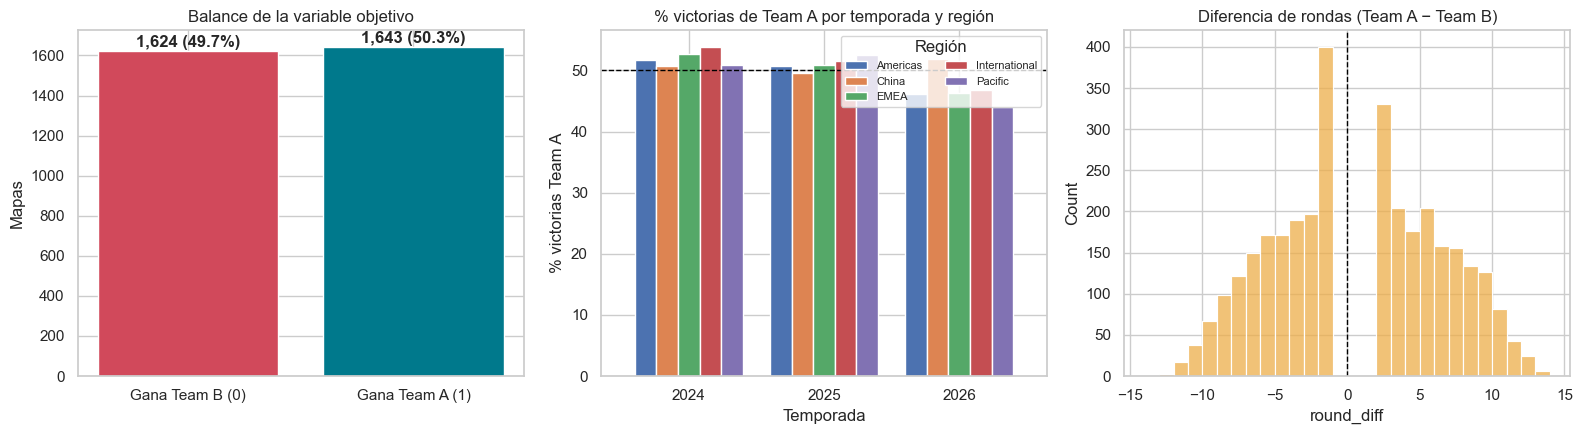

Balance: 50.3% gana Team A / 49.7% gana Team B  -> clases balanceadas, no se requiere re-muestreo.
round_diff: media = 0.19, mediana = 2, desv. std = 5.93
Mapas decididos por 1-3 rondas (13-10 a 13-12 u overtime): 34.6%


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 4.1 Balance de clases
counts = df["team_a_wins"].value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(1)
axes[0].bar(["Gana Team B (0)", "Gana Team A (1)"], counts.values, color=["#d1495b", "#00798c"])
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    axes[0].text(i, c + 20, f"{c:,} ({p}%)", ha="center", fontweight="bold")
axes[0].set_title("Balance de la variable objetivo")
axes[0].set_ylabel("Mapas")

# 4.2 Tasa de victoria de Team A por temporada y región
wr = df.groupby(["year", "region"])["team_a_wins"].mean().unstack() * 100
wr.plot(kind="bar", ax=axes[1], width=0.8)
axes[1].axhline(50, color="black", ls="--", lw=1)
axes[1].set_title("% victorias de Team A por temporada y región")
axes[1].set_ylabel("% victorias Team A"); axes[1].set_xlabel("Temporada")
axes[1].legend(title="Región", fontsize=8, ncol=2)
axes[1].tick_params(axis="x", rotation=0)

# 4.3 Distribución de la diferencia de rondas
sns.histplot(df["round_diff"], bins=range(-14, 15), ax=axes[2], color="#edae49")
axes[2].axvline(0, color="black", ls="--", lw=1)
axes[2].set_title("Diferencia de rondas (Team A − Team B)")
axes[2].set_xlabel("round_diff")
plt.tight_layout(); plt.show()

print(f"Balance: {pct[1]}% gana Team A / {pct[0]}% gana Team B  -> clases balanceadas, no se requiere re-muestreo.")
print(f"round_diff: media = {df['round_diff'].mean():.2f}, mediana = {df['round_diff'].median():.0f}, "
      f"desv. std = {df['round_diff'].std():.2f}")
print(f"Mapas decididos por 1-3 rondas (13-10 a 13-12 u overtime): {(df['round_diff'].abs() <= 3).mean()*100:.1f}%")

**Lectura:** la clase está **balanceada** (~50/50), lo cual es esperable porque "Team A" es simplemente el primer equipo
listado en vlr.gg, no el favorito. Esto es una buena noticia: el modelo no partirá con un sesgo de posición
y la métrica *accuracy* será interpretable (una moneda al aire da 50%).

La diferencia de rondas es **bimodal y simétrica** alrededor de 0 (no hay valores entre −1 y 1 porque siempre hay
ganador), con colas hacia ±13. Un porcentaje alto de mapas se decide por pocas rondas: el resultado tiene
mucha varianza intrínseca, lo que **justifica predecir probabilidades y no solo un ganador**.

## 5. Análisis de distribuciones

El dataset consolidado tiene **80 columnas**, más de 20 características. Siguiendo las instrucciones,
analizamos en detalle **las variables más correlacionadas con la variable objetivo** más las variables
de contexto necesarias para entender el problema.

### Regla de reporte (estándar del curso)

| Tipo | Gráfico | Estadísticas |
|---|---|---|
| Categórica | Barras / pastel | Frecuencia y porcentaje |
| Numérica simétrica | Histograma en forma de campana | Media ± desviación estándar |
| Numérica asimétrica / con outliers | Histograma sesgado o boxplot con puntos lejanos | Mediana y rango intercuartil (IQR) |

Para decidir objetivamente entre "simétrica" y "asimétrica" usamos, además de la inspección visual,
el **coeficiente de asimetría (skewness)**: |skew| < 0.5 → aproximadamente simétrica.

In [4]:
def reportar_categorica(col, ax=None, top=None, titulo=None):
    '''Barras con frecuencia y porcentaje.'''
    vc = df[col].value_counts()
    if top: vc = vc.head(top)
    pct = vc / len(df) * 100
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(vc.index.astype(str), vc.values, color=sns.color_palette("deep", len(vc)))
    for b, c, p in zip(bars, vc.values, pct.values):
        ax.text(b.get_x() + b.get_width()/2, c + len(df)*0.005, f"{c}\n({p:.1f}%)", ha="center", fontsize=8)
    ax.set_title(titulo or col); ax.set_ylabel("Mapas")
    ax.tick_params(axis="x", rotation=45)
    return vc, pct


def reportar_numerica(col, ax_hist=None, ax_box=None, titulo=None):
    '''Histograma + boxplot y decide qué estadísticas reportar según la asimetría.'''
    s = df[col].dropna()
    skew = s.skew()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()
    if ax_hist is None:
        fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [3, 1]})
    sns.histplot(s, kde=True, ax=ax_hist, color="#00798c")
    ax_hist.axvline(s.mean(), color="#d1495b", ls="--", label=f"media {s.mean():.2f}")
    ax_hist.axvline(s.median(), color="#edae49", ls="-", label=f"mediana {s.median():.2f}")
    ax_hist.legend(fontsize=8); ax_hist.set_title(titulo or col)
    sns.boxplot(y=s, ax=ax_box, color="#edae49", fliersize=2)
    ax_box.set_title(f"skew = {skew:.2f}\noutliers = {n_out}", fontsize=9)
    if abs(skew) < 0.5:
        tipo, rep = "Simétrica", f"media = {s.mean():.2f} ± {s.std():.2f}"
    else:
        tipo, rep = "Asimétrica", f"mediana = {s.median():.2f}, IQR = [{q1:.2f} – {q3:.2f}], rango = [{s.min():.2f} – {s.max():.2f}]"
    return {"variable": col, "tipo": tipo, "skew": round(skew, 2), "n_outliers_IQR": int(n_out),
            "nulos_%": round(df[col].isna().mean()*100, 1), "reporte": rep}

### 5.1 Selección de variables: correlación con la variable objetivo

Calculamos la correlación de todas las variables numéricas con `team_a_wins` (correlación punto-biserial,
equivalente a Pearson con una variable binaria). Las variables `*_diff` (Team A − Team B) son las
naturales para un problema de "quién gana", porque lo que importa es la **ventaja relativa**.

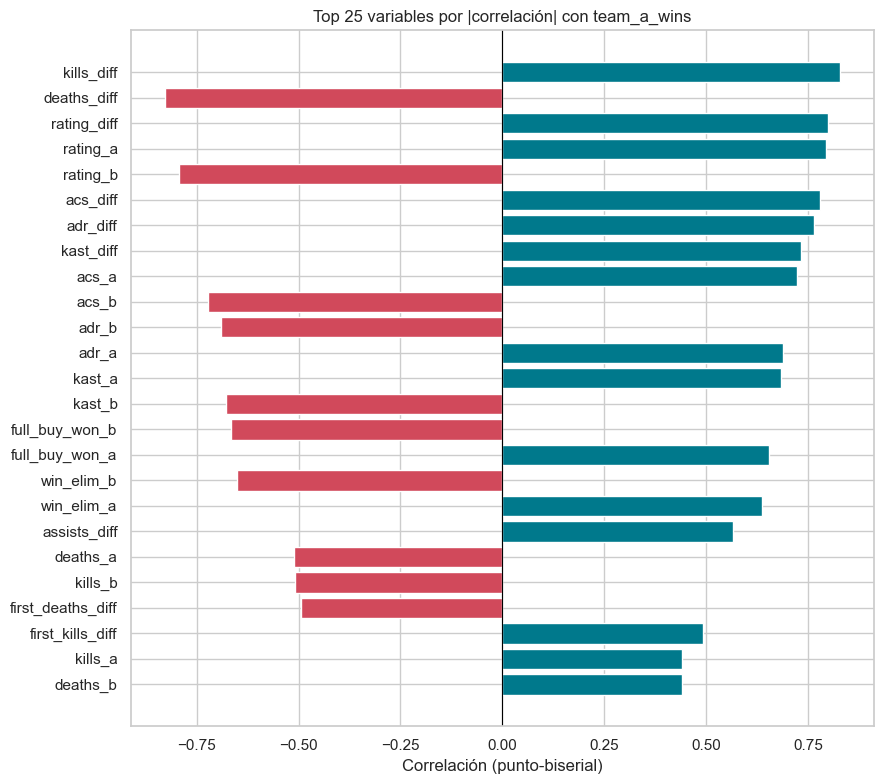

kills_diff        0.829
deaths_diff      -0.828
rating_diff       0.798
rating_a          0.794
rating_b         -0.792
acs_diff          0.780
adr_diff          0.765
kast_diff         0.733
acs_a             0.722
acs_b            -0.722
adr_b            -0.690
adr_a             0.689
kast_a            0.683
kast_b           -0.679
full_buy_won_b   -0.665


In [5]:
num_cols = df.select_dtypes(include="number").columns.drop(["team_a_wins", "score_a", "score_b", "round_diff",
                                                            "atk_score_a", "def_score_a", "atk_score_b", "def_score_b",
                                                            "ot_score_a", "ot_score_b", "match_id", "game_id",
                                                            "tournament_id", "stage_id", "team_a_id", "team_b_id", "year"])
corr_target = df[num_cols].corrwith(df["team_a_wins"]).sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(9, 8))
top = corr_target.head(25)
colors = ["#00798c" if v > 0 else "#d1495b" for v in top.values]
ax.barh(top.index[::-1], top.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Top 25 variables por |correlación| con team_a_wins")
ax.set_xlabel("Correlación (punto-biserial)")
plt.tight_layout(); plt.show()

print(corr_target.head(15).round(3).to_string())

**Lectura:** las variables que dominan son las diferencias de rendimiento **dentro del mismo mapa**
(`rating_diff`, `acs_diff`, `kast_diff`, `adr_diff`, `kills_diff`…). Es lógico: quien mata más y muere menos gana.

⚠️ **Advertencia de *leakage*:** estas estadísticas se registran **durante** el mapa que queremos predecir.
En el EDA sirven para entender *qué explica la victoria*, pero en el modelo final solo podremos usar
**versiones históricas** (rendimiento del equipo en los mapas *anteriores*). Ese cruce se explora en la sección 7.5.

### 5.2 Variables categóricas

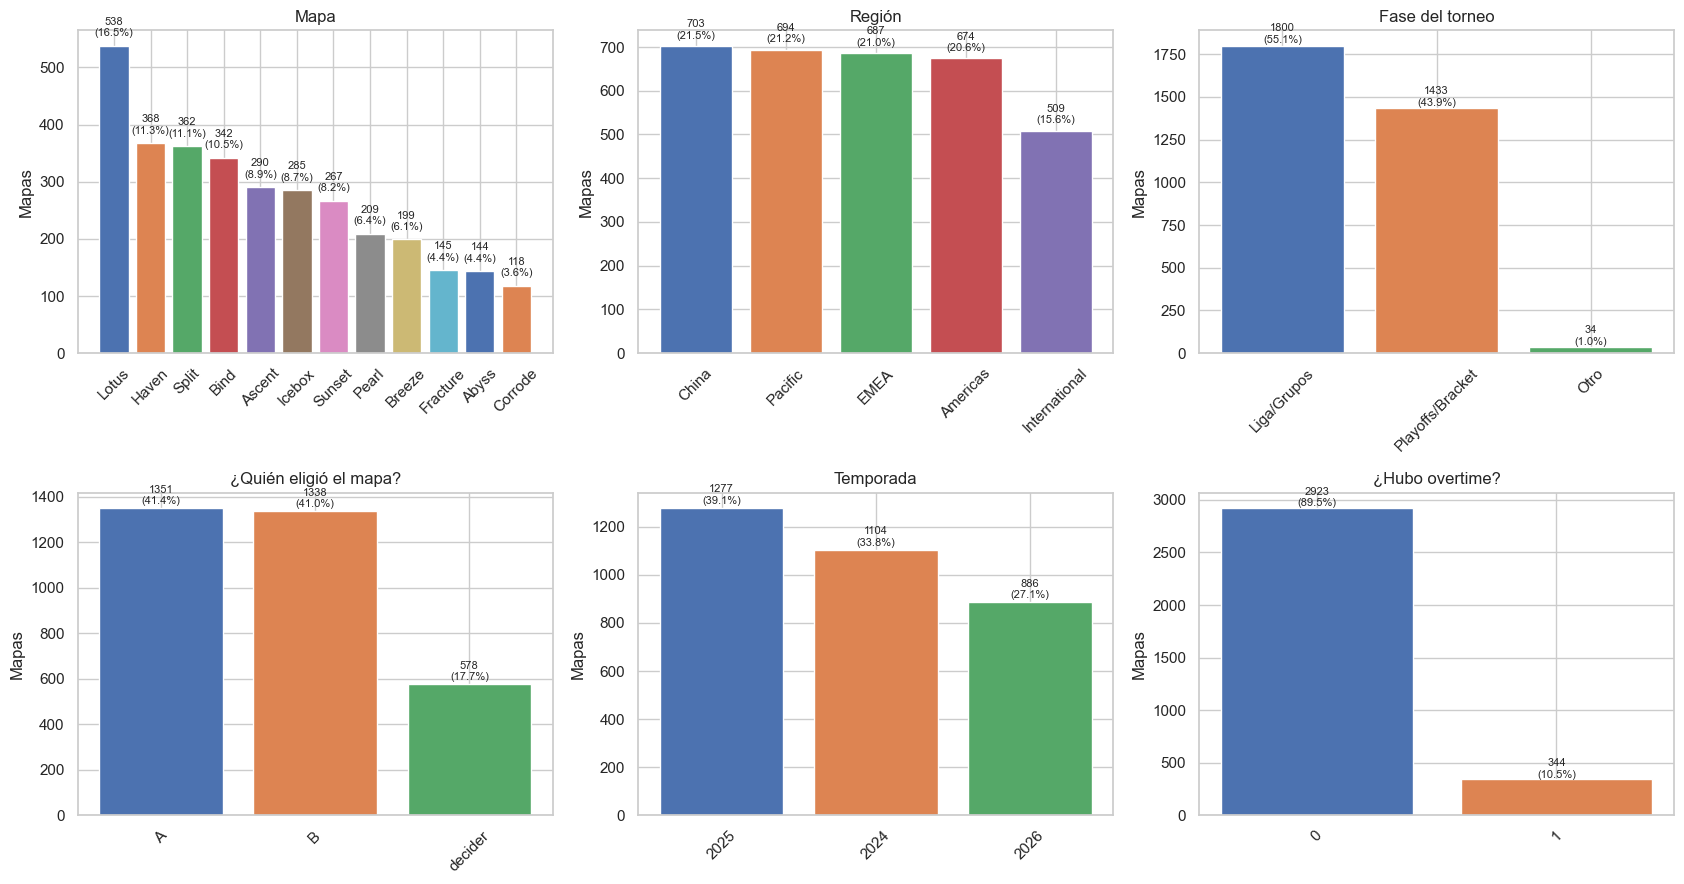

Mapa                       -> Lotus: 538 (16.5%), Haven: 368 (11.3%), Split: 362 (11.1%)
Región                     -> China: 703 (21.5%), Pacific: 694 (21.2%), EMEA: 687 (21.0%)
Fase del torneo            -> Liga/Grupos: 1800 (55.1%), Playoffs/Bracket: 1433 (43.9%), Otro: 34 (1.0%)
¿Quién eligió el mapa?     -> A: 1351 (41.4%), B: 1338 (41.0%), decider: 578 (17.7%)
Temporada                  -> 2025: 1277 (39.1%), 2024: 1104 (33.8%), 2026: 886 (27.1%)
¿Hubo overtime?            -> 0: 2923 (89.5%), 1: 344 (10.5%)


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
cat_vars = [("map", "Mapa"), ("region", "Región"), ("stage_group", "Fase del torneo"),
            ("map_picked_by", "¿Quién eligió el mapa?"), ("year", "Temporada"), ("overtime", "¿Hubo overtime?")]
for ax, (col, t) in zip(axes.ravel(), cat_vars):
    reportar_categorica(col, ax=ax, titulo=t)
plt.tight_layout(); plt.show()

for col, t in cat_vars:
    vc = df[col].value_counts(); pct = (vc/len(df)*100).round(1)
    top2 = ", ".join(f"{k}: {v} ({p}%)" for k, v, p in list(zip(vc.index, vc.values, pct.values))[:3])
    print(f"{t:26s} -> {top2}")

**Lectura de las categóricas (frecuencia y %):**
- **Mapa:** el pool competitivo rota cada temporada; ningún mapa domina, pero hay mapas con muchas menos
  muestras (los que entraron/salieron del pool). Habrá que tenerlo en cuenta al codificar la variable.
- **Región:** las cuatro ligas regionales están equilibradas (~21% cada una); los torneos internacionales
  (Masters/Champions) aportan ~16% de los mapas.
- **Fase:** ~55% de los mapas son de liga regular / fase de grupos y ~44% de brackets eliminatorios (playoffs y *main events* de Kickoff); play-ins y showmatches son residuales.
- **Quién eligió el mapa:** ~41% Team A, ~41% Team B y ~18% mapas *decider* (el que queda tras los bans).
- **Overtime:** solo ~10% de los mapas llegan a overtime: son partidos muy parejos, un caso especialmente difícil para el casino.

### 5.3 Variables numéricas más relevantes

Analizamos las diferencias (A − B) más correlacionadas con el target y las variables de resultado.

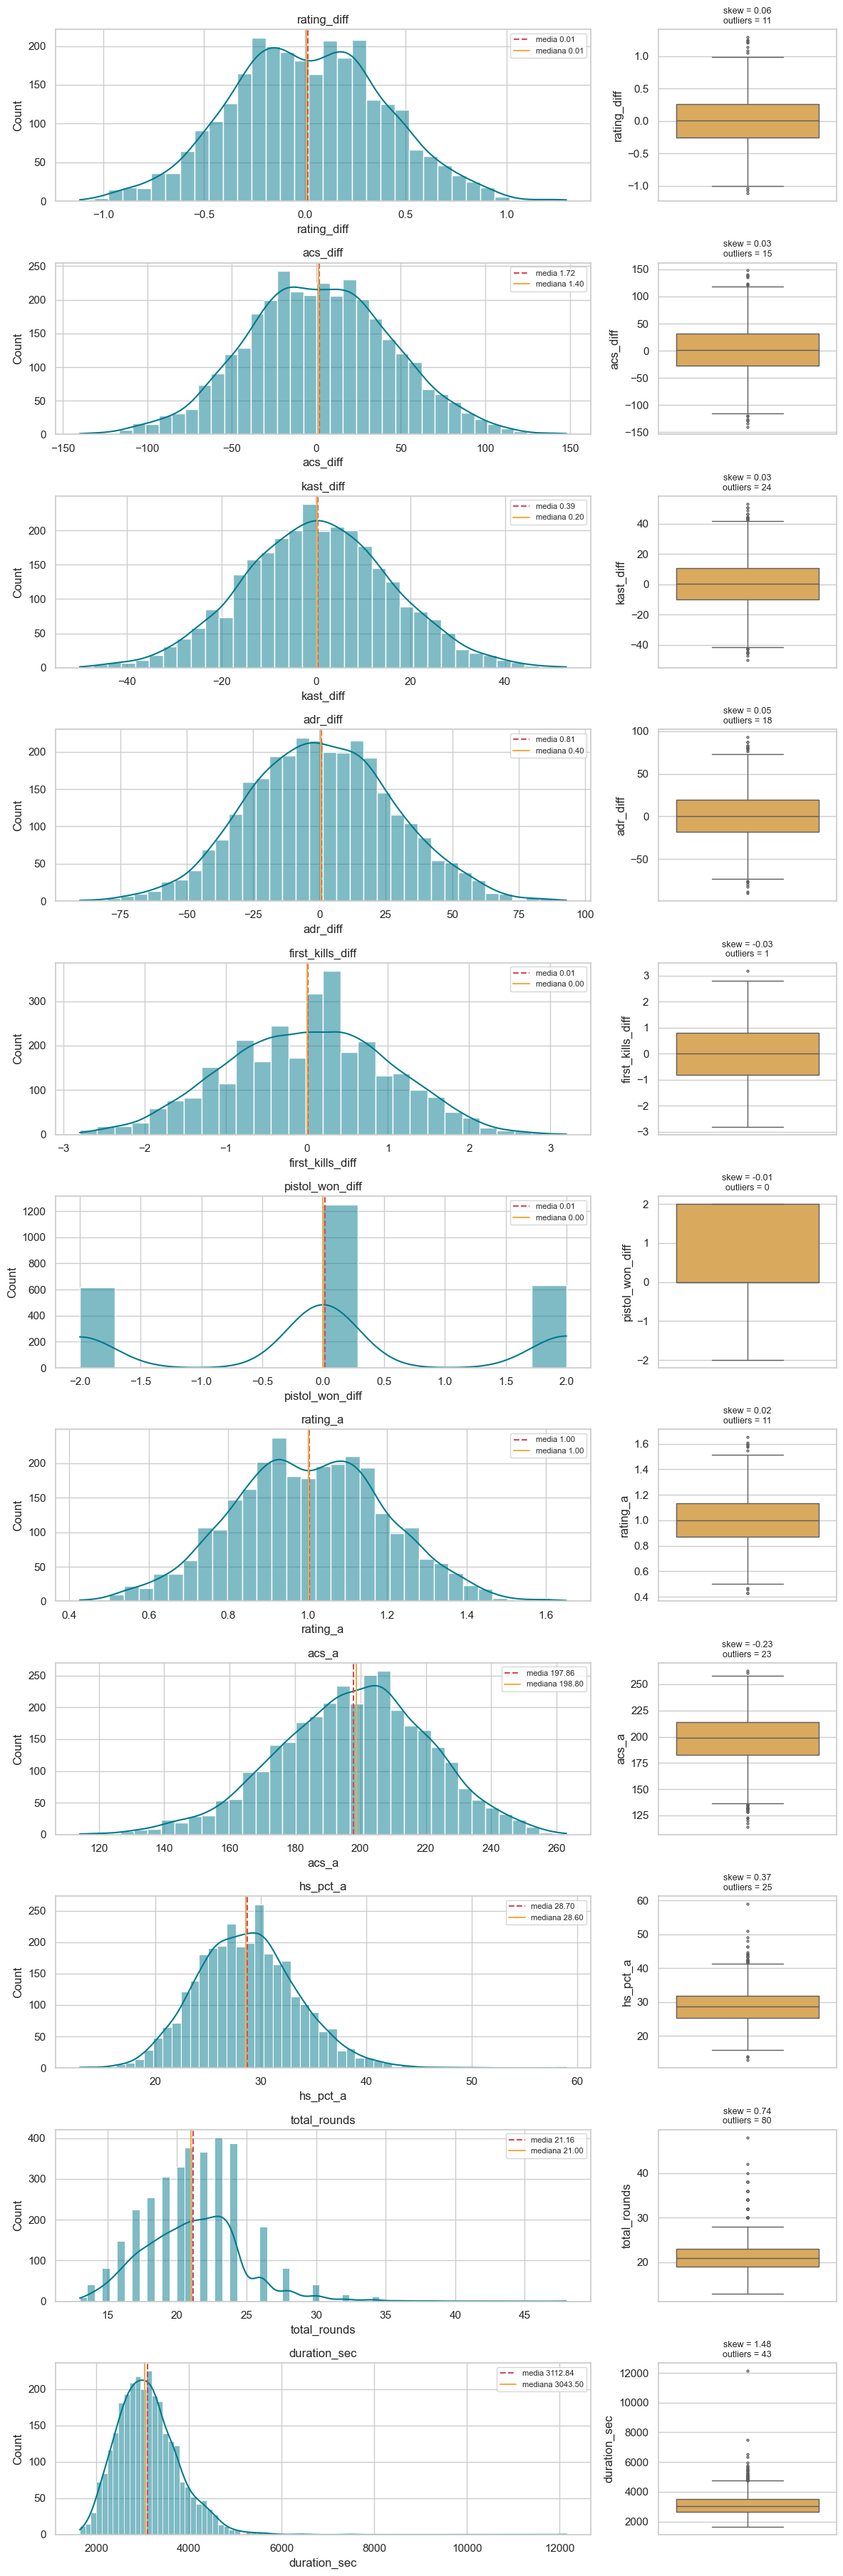

,variable,tipo,skew,n_outliers_IQR,nulos_%,reporte
0,rating_diff,Simétrica,0.06,11,12.5,media = 0.01 ± 0.38
1,acs_diff,Simétrica,0.03,15,0.2,media = 1.72 ± 43.22
2,kast_diff,Simétrica,0.03,24,12.2,media = 0.39 ± 15.73
3,adr_diff,Simétrica,0.05,18,7.8,media = 0.81 ± 27.38
4,first_kills_diff,Simétrica,-0.03,1,7.8,media = 0.01 ± 1.00
5,pistol_won_diff,Simétrica,-0.01,0,23.6,media = 0.01 ± 1.41
6,rating_a,Simétrica,0.02,11,12.5,media = 1.00 ± 0.19
7,acs_a,Simétrica,-0.23,23,0.2,media = 197.86 ± 23.14
8,hs_pct_a,Simétrica,0.37,25,7.7,media = 28.70 ± 4.80
9,total_rounds,Asimétrica,0.74,80,0.0,"mediana = 21.00, IQR = [19.00 – 23.00], rango ..."


In [7]:
num_vars = ["rating_diff", "acs_diff", "kast_diff", "adr_diff", "first_kills_diff", "pistol_won_diff",
            "rating_a", "acs_a", "hs_pct_a", "total_rounds", "duration_sec"]
resumen = []
fig, axes = plt.subplots(len(num_vars), 2, figsize=(12, 3.3*len(num_vars)), gridspec_kw={"width_ratios": [3, 1]})
for (ax_h, ax_b), col in zip(axes, num_vars):
    resumen.append(reportar_numerica(col, ax_h, ax_b))
plt.tight_layout(); plt.show()

resumen = pd.DataFrame(resumen)
resumen

**Lectura de las numéricas** (la tabla anterior aplica la regla automáticamente):

- Las **diferencias** (`rating_diff`, `acs_diff`, `kast_diff`, `adr_diff`, `first_kills_diff`) son
  **simétricas y centradas en 0** — se reportan con **media ± desviación estándar**. Tiene sentido: al restar
  A − B, la ventaja se reparte por igual entre ambos lados.
- `rating_a`, `acs_a`, `hs_pct_a` (nivel absoluto del equipo) son aproximadamente **simétricas**,
  con algunos outliers en las colas (mapas muy desiguales).
- `total_rounds` y `duration_sec` son **asimétricas a la derecha** (sesgo positivo): la mayoría de mapas
  terminan en 13–x, pero los overtime alargan la cola → se reportan con **mediana e IQR**.
- `pistol_won_diff` es discreta (−2, −1, 0, 1, 2); se trata como numérica ordinal.

## 6. Calidad de datos: nulos y valores atípicos

### 6.1 Valores nulos

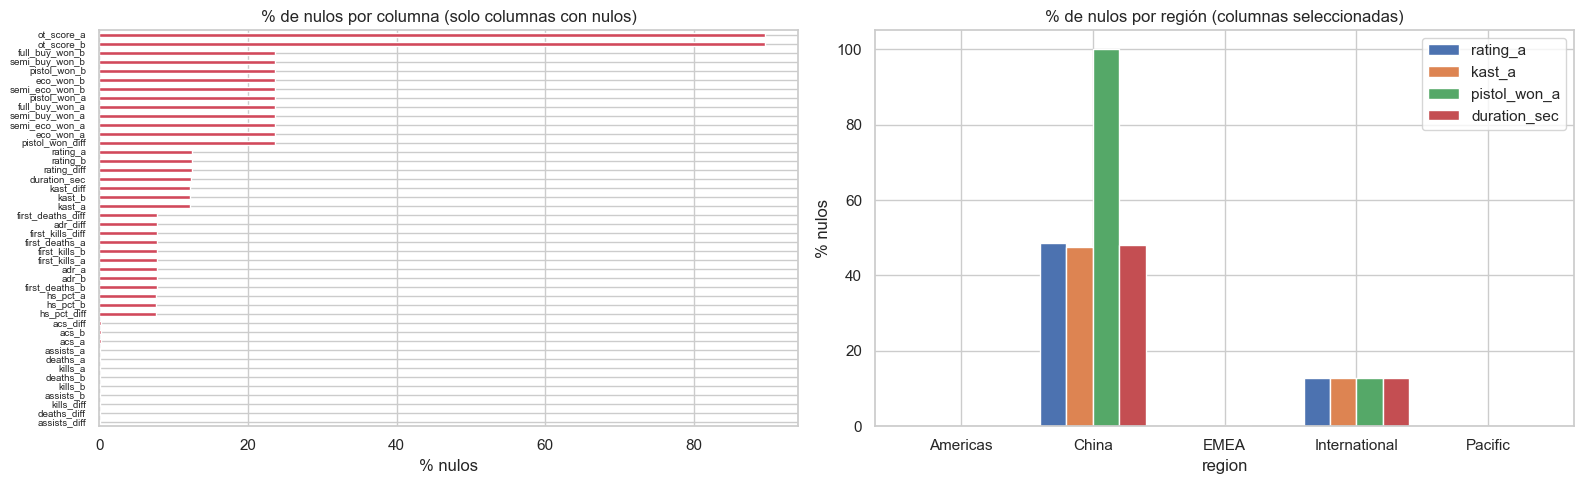

               rating_a  kast_a  pistol_won_a  duration_sec
region                                                     
Americas            0.0     0.0           0.0           0.0
China              48.5    47.5         100.0          48.2
EMEA                0.3     0.1           0.3           0.1
International      12.8    12.8          12.8          12.8
Pacific             0.0     0.0           0.0           0.0


In [8]:
nulos = (df.isna().mean()*100).round(1)
nulos = nulos[nulos > 0].sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
nulos.plot(kind="barh", ax=axes[0], color="#d1495b")
axes[0].set_title("% de nulos por columna (solo columnas con nulos)"); axes[0].set_xlabel("% nulos")
axes[0].invert_yaxis(); axes[0].tick_params(axis="y", labelsize=7)

# ¿De dónde vienen los nulos? -> por región
nul_reg = df.groupby("region")[["rating_a", "kast_a", "pistol_won_a", "duration_sec"]].apply(lambda g: g.isna().mean()*100).round(1)
nul_reg.plot(kind="bar", ax=axes[1], width=0.8)
axes[1].set_title("% de nulos por región (columnas seleccionadas)"); axes[1].set_ylabel("% nulos")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print(nul_reg.to_string())

**Diagnóstico de los nulos** (cruzando con la región se ve claramente el origen):

| Grupo de columnas | % nulos | Causa | Estrategia |
|---|---|---|---|
| `ot_score_a/b` | ~90% | El mapa **no llegó a overtime** — nulo = "no ocurrió" | Ya está capturado en `overtime` (0/1); imputar 0 o eliminar la columna |
| Economía (`pistol_won_*`, `eco_won_*`, …) | ~24% | vlr.gg no publica datos de economía de los matches de **China** | Imputar con la mediana del mapa **o** entrenar con indicador de "dato faltante"; evaluar el modelo con y sin estas columnas |
| `rating_*`, `kast_*` | ~12% | Post-match incompleto (mayoría en China) | Igual que economía; `acs`/`kills` sí están → se pueden usar como *proxy* |
| `adr_*`, `hs_pct_*`, `first_kills_*` | ~8% | Igual | Imputación por mediana del equipo |
| `duration_sec` | ~12% | No disponible en vlr.gg | No es una variable predictiva (solo se conoce al terminar) → no se usará como *feature* |

Ningún nulo afecta a la **variable objetivo** ni a las variables de contexto (`map`, `region`, `map_picked_by`).

### 6.2 Valores atípicos (outliers)

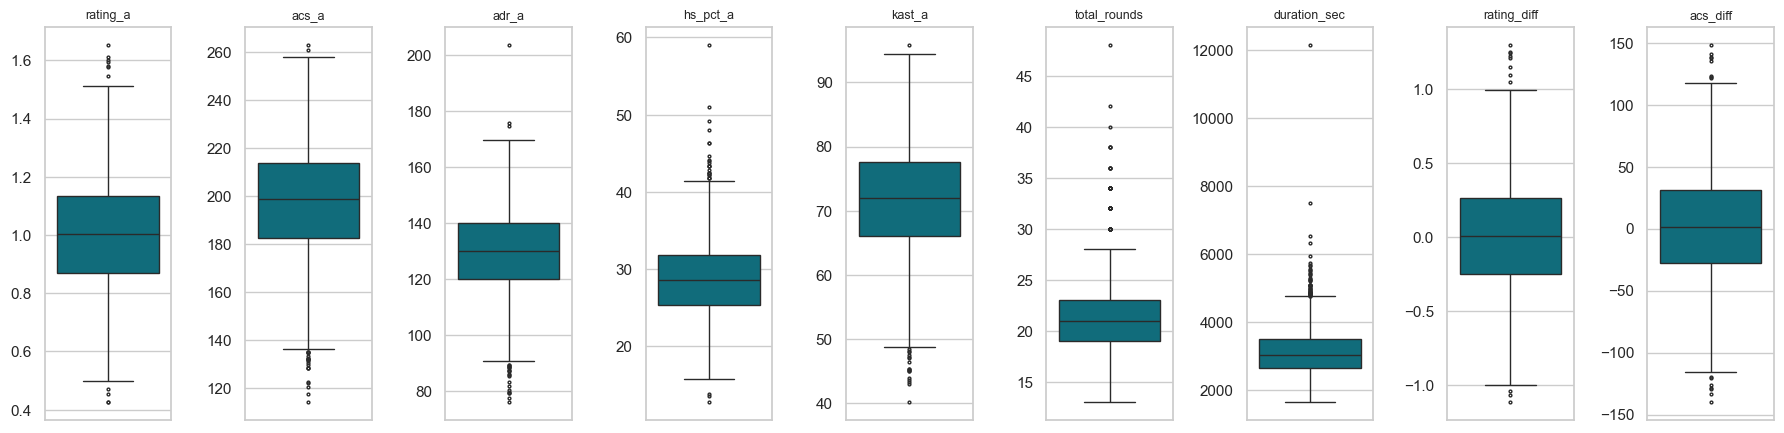

Mapas más largos (duration_sec):
                          tournament                 match_name    map  score_a  score_b  duration_sec
Champions Tour 2024: Pacific Kickoff                T1 vs BLEED Breeze       18       16       12151.0
              VCT 2025: EMEA Stage 1 BBL Esports vs FUT Esports Ascent       25       23        7500.0
       Valorant Masters Toronto 2025            FNATIC vs Gen.G  Split       14       12        6522.0

Mapas con rating promedio de equipo más alto (paliza):
                          tournament                    match_name    map  score_a  score_b  rating_a
Champions Tour 2024: Pacific Stage 1    Paper Rex vs Talon Esports  Lotus       13        0     1.652
          VCT 2025: Americas Stage 2       Cloud9 vs 2Game Esports   Bind       13        1     1.612
             VCT 2025: China Stage 1 Xi Lai Gaming vs Nova Esports Ascent       13        2     1.600

Mapas con más rondas:
                tournament                          match_name    ma

In [9]:
out_cols = ["rating_a", "acs_a", "adr_a", "hs_pct_a", "kast_a", "total_rounds", "duration_sec", "rating_diff", "acs_diff"]
fig, axes = plt.subplots(1, len(out_cols), figsize=(18, 4.5))
for ax, c in zip(axes, out_cols):
    sns.boxplot(y=df[c], ax=ax, color="#00798c", fliersize=2)
    ax.set_title(c, fontsize=9); ax.set_ylabel("")
plt.tight_layout(); plt.show()

# Ejemplos concretos de outliers
print("Mapas más largos (duration_sec):")
print(df.nlargest(3, "duration_sec")[["tournament", "match_name", "map", "score_a", "score_b", "duration_sec"]].to_string(index=False))
print("\nMapas con rating promedio de equipo más alto (paliza):")
print(df.nlargest(3, "rating_a")[["tournament", "match_name", "map", "score_a", "score_b", "rating_a"]].to_string(index=False))
print("\nMapas con más rondas:")
print(df.nlargest(3, "total_rounds")[["tournament", "match_name", "map", "score_a", "score_b", "total_rounds"]].to_string(index=False))

**Diagnóstico de outliers:** los puntos fuera de los bigotes son **valores reales, no errores**:
- `total_rounds` > 24 y `duration_sec` altos son mapas con **overtime largo** (p. ej. 16-14 o más).
- `rating_a` ≈ 1.6+ o `acs_a` > 300 corresponden a **palizas** (13-2, 13-3): un equipo domina y todos sus jugadores brillan.
- `hs_pct_a` muy alto/bajo se da en mapas cortos, con pocas rondas → pocas muestras por jugador.

**Estrategia:** no eliminarlos (son partidos legítimos y el casino necesita predecir también esos).
Para modelos sensibles a escala (regresión logística, SVM, redes) se usará **estandarización robusta**
(mediana/IQR) o *clipping* a percentiles 1–99. Los modelos de árboles (Random Forest, XGBoost) no se ven afectados.

Otros problemas de calidad tratados en la construcción del dataset (`src/build_dataset.py`):
- Porcentajes en texto (`"91%"`) y duraciones (`"48:56"`) → convertidos a numérico.
- Jugador llamado literalmente `"nan"` → se lee como texto, no como nulo.
- Equipos con nombre repetido (`Exotic`) o abreviatura repetida (`TP`) → se usa `team_id`.
- Mapas con **11 jugadores** en `overview` (sustituciones a mitad de match): 2 casos, se promedian igual.

## 7. Patrones e insights

### 7.1 Matriz de correlación entre las variables más relevantes

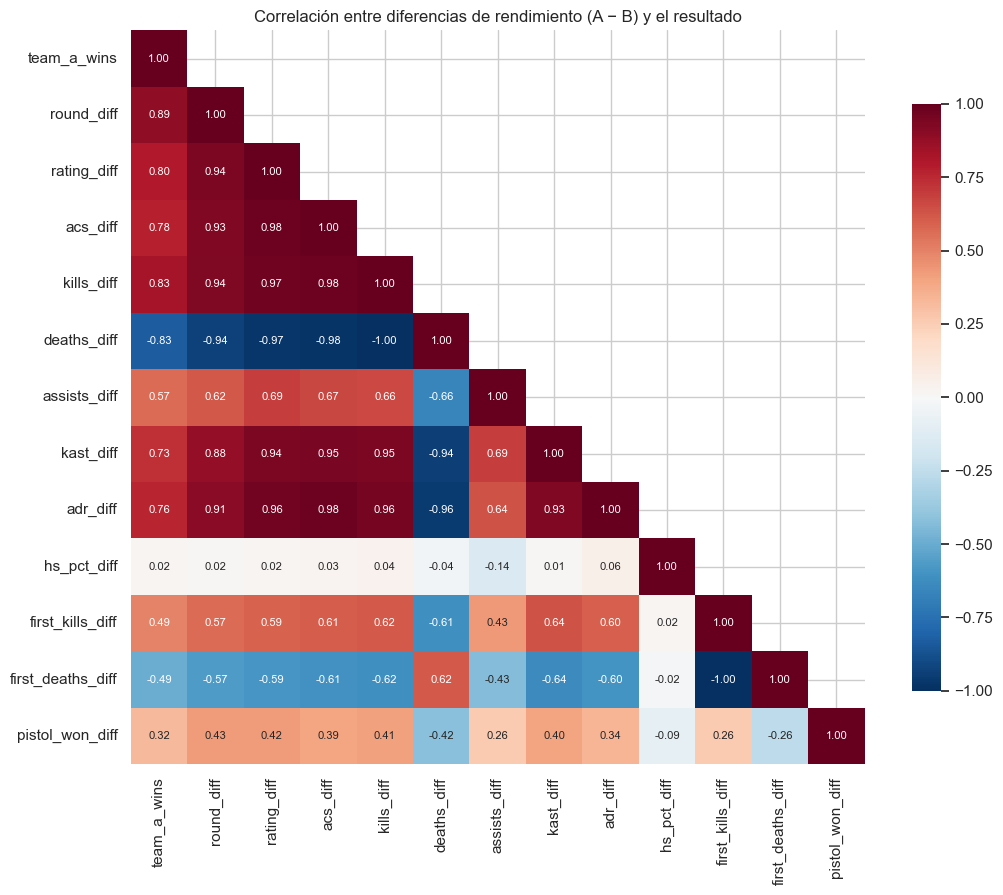

In [10]:
corr_vars = ["team_a_wins", "round_diff", "rating_diff", "acs_diff", "kills_diff", "deaths_diff", "assists_diff",
             "kast_diff", "adr_diff", "hs_pct_diff", "first_kills_diff", "first_deaths_diff", "pistol_won_diff"]
corr = df[corr_vars].corr()
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlación entre diferencias de rendimiento (A − B) y el resultado")
plt.tight_layout(); plt.show()

**Lectura:**
- `rating_diff`, `acs_diff`, `kills_diff` y `kast_diff` están **muy correlacionadas entre sí** (> 0.85):
  miden lo mismo (dominio en el mapa). Para el modelo conviene quedarse con una o dos (p. ej. `rating` que ya las resume)
  o usar regularización para evitar **multicolinealidad**.
- `hs_pct_diff` (precisión) tiene correlación **débil** con ganar: apuntar bien a la cabeza no decide mapas; la
  posición y el juego en equipo pesan más.
- `first_kills_diff` y `pistol_won_diff` tienen correlación moderada y son **más independientes** del resto:
  aportan información distinta.

### 7.2 ¿Gana más el equipo que elige el mapa?

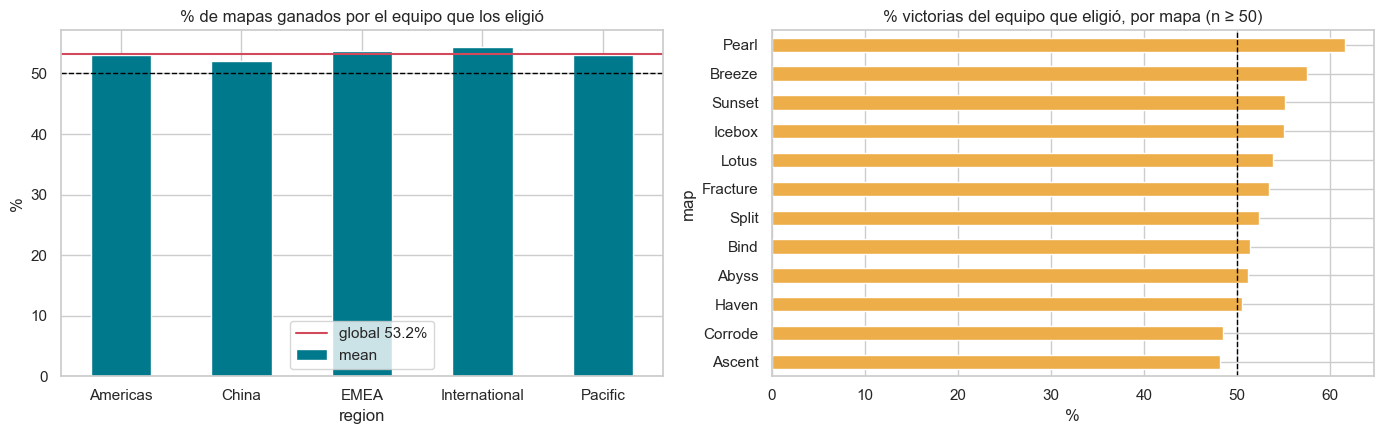

El equipo que elige el mapa lo gana el 53.2% de las veces (n = 2689).
Win rate de Team A en mapas decider: 54.5%


In [11]:
picker = df.copy()
picker["ganó_el_que_eligió"] = np.where(picker["map_picked_by"] == "A", picker["team_a_wins"],
                               np.where(picker["map_picked_by"] == "B", 1 - picker["team_a_wins"], np.nan))
tab = picker.dropna(subset=["ganó_el_que_eligió"]).groupby("region")["ganó_el_que_eligió"].agg(["mean", "count"])
tab["mean"] *= 100
overall = picker["ganó_el_que_eligió"].mean()*100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
tab["mean"].plot(kind="bar", ax=axes[0], color="#00798c")
axes[0].axhline(50, color="black", ls="--", lw=1)
axes[0].axhline(overall, color="#d1495b", ls="-", lw=1.5, label=f"global {overall:.1f}%")
axes[0].set_title("% de mapas ganados por el equipo que los eligió"); axes[0].set_ylabel("%"); axes[0].legend()
axes[0].tick_params(axis="x", rotation=0)

# Por mapa
tab_map = picker.dropna(subset=["ganó_el_que_eligió"]).groupby("map")["ganó_el_que_eligió"].agg(["mean", "count"])
tab_map = tab_map[tab_map["count"] >= 50].sort_values("mean")
(tab_map["mean"]*100).plot(kind="barh", ax=axes[1], color="#edae49")
axes[1].axvline(50, color="black", ls="--", lw=1)
axes[1].set_title("% victorias del equipo que eligió, por mapa (n ≥ 50)"); axes[1].set_xlabel("%")
plt.tight_layout(); plt.show()

print(f"El equipo que elige el mapa lo gana el {overall:.1f}% de las veces (n = {picker['ganó_el_que_eligió'].notna().sum()}).")
print(f"Win rate de Team A en mapas decider: {df.loc[df.map_picked_by=='decider','team_a_wins'].mean()*100:.1f}%")

**Insight:** el equipo que elige el mapa lo gana **el 53.2% de las veces** (ventaja de ~3 puntos sobre el 50%,
con n ≈ 2,700 mapas, así que no es ruido). Es una variable **conocida antes de empezar el mapa** → es una *feature* legítima y valiosa
para el casino. La ventaja varía por mapa, lo que sugiere una interacción `map × map_picked_by`.

### 7.3 Rondas pistola y primeras sangres: ¿cuánto pesan?

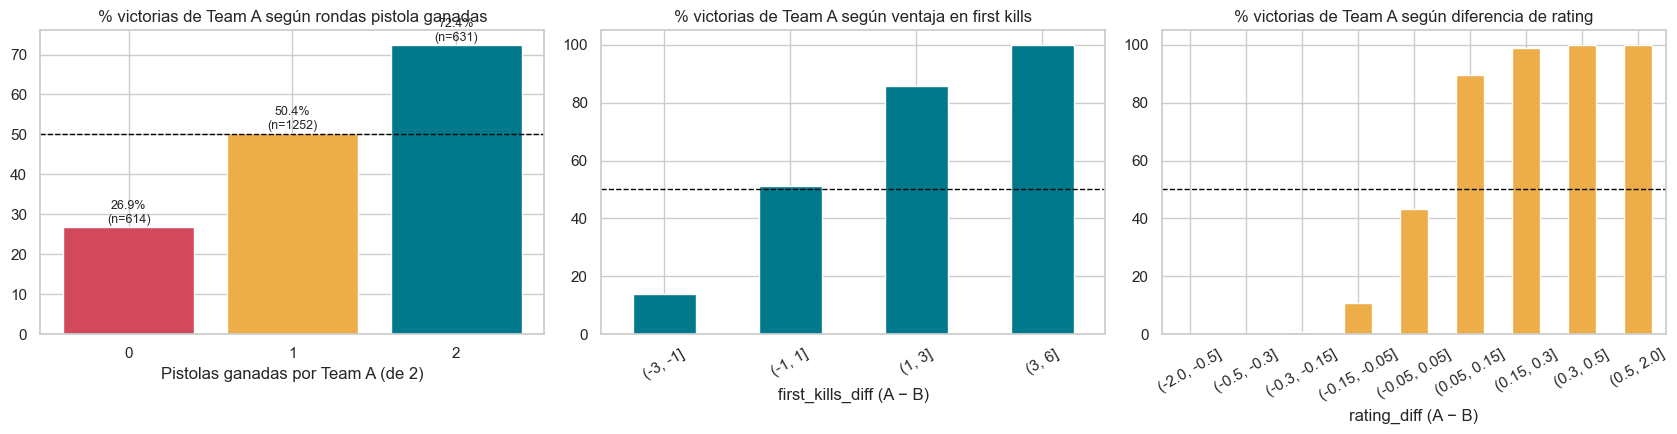

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Pistolas ganadas por Team A (0, 1, 2) vs win rate
p = df.dropna(subset=["pistol_won_a"]).groupby("pistol_won_a")["team_a_wins"].agg(["mean", "count"])
axes[0].bar(p.index.astype(int).astype(str), p["mean"]*100, color=["#d1495b", "#edae49", "#00798c"])
for i, (m, c) in enumerate(zip(p["mean"], p["count"])):
    axes[0].text(i, m*100 + 1, f"{m*100:.1f}%\n(n={c})", ha="center", fontsize=9)
axes[0].axhline(50, color="black", ls="--", lw=1)
axes[0].set_title("% victorias de Team A según rondas pistola ganadas"); axes[0].set_xlabel("Pistolas ganadas por Team A (de 2)")

# first_kills_diff en bins
bins = pd.cut(df["first_kills_diff"], [-30, -6, -3, -1, 1, 3, 6, 30])
fk = df.groupby(bins, observed=True)["team_a_wins"].mean()*100
fk.plot(kind="bar", ax=axes[1], color="#00798c")
axes[1].axhline(50, color="black", ls="--", lw=1)
axes[1].set_title("% victorias de Team A según ventaja en first kills"); axes[1].set_xlabel("first_kills_diff (A − B)")
axes[1].tick_params(axis="x", rotation=30)

# rating_diff en bins
bins = pd.cut(df["rating_diff"], [-2, -0.5, -0.3, -0.15, -0.05, 0.05, 0.15, 0.3, 0.5, 2])
rt = df.groupby(bins, observed=True)["team_a_wins"].mean()*100
rt.plot(kind="bar", ax=axes[2], color="#edae49")
axes[2].axhline(50, color="black", ls="--", lw=1)
axes[2].set_title("% victorias de Team A según diferencia de rating"); axes[2].set_xlabel("rating_diff (A − B)")
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**Insights:**
- Ganar **las dos rondas pistola** dispara la probabilidad de ganar el mapa (≈ 75–80%), y perder ambas la hunde:
  solo 2 rondas de 24 explican una gran parte del resultado, porque encadenan ventaja económica.
- La relación entre `rating_diff` y ganar es **monótona y en forma de S** (sigmoide): exactamente la forma que
  asume una **regresión logística**, buen candidato de modelo base.
- Una ventaja de ±0.15 de rating ya separa claramente ganadores de perdedores.

### 7.4 Efecto del mapa: lado atacante vs defensor y overtime

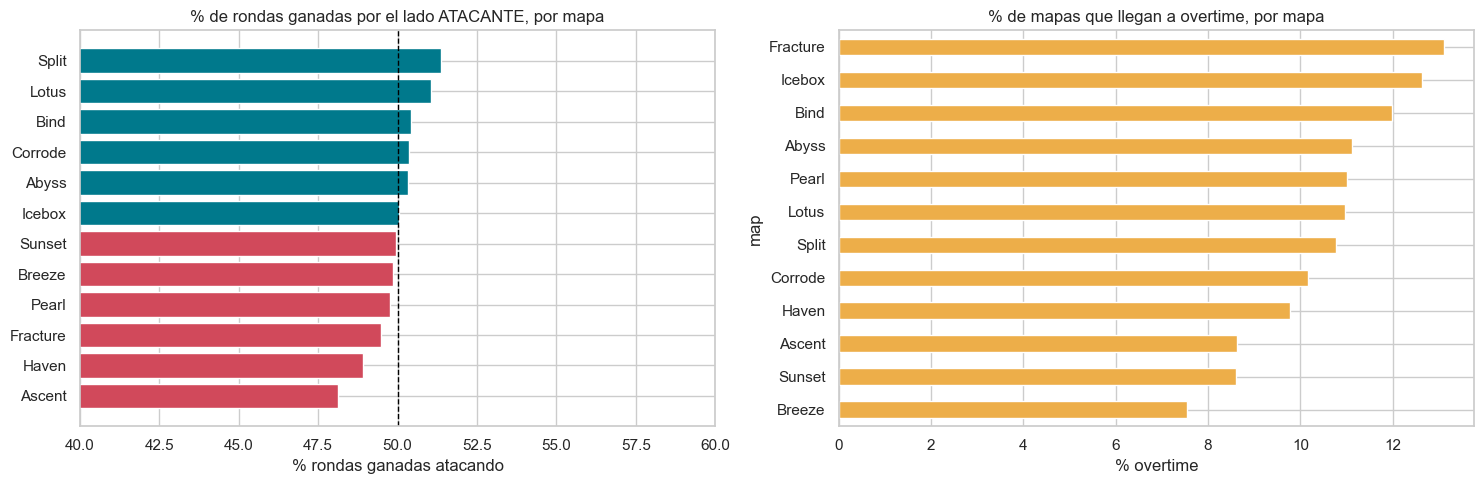

            n  atk_win_pct  overtime
map                                 
Ascent    290       48.130     0.086
Haven     368       48.914     0.098
Fracture  145       49.487     0.131
Pearl     209       49.756     0.110
Breeze    199       49.854     0.075
Sunset    267       49.955     0.086
Icebox    285       50.034     0.126
Abyss     144       50.318     0.111
Corrode   118       50.368     0.102
Bind      342       50.410     0.120
Lotus     538       51.043     0.110
Split     362       51.370     0.108


In [13]:
side = df.groupby("map").agg(
    atk_rounds=("atk_score_a", "sum"), def_rounds=("def_score_a", "sum"),
    atk_rounds_b=("atk_score_b", "sum"), def_rounds_b=("def_score_b", "sum"),
    overtime=("overtime", "mean"), n=("map", "size"))
side["atk_win_pct"] = (side["atk_rounds"] + side["atk_rounds_b"]) / (side[["atk_rounds", "def_rounds", "atk_rounds_b", "def_rounds_b"]].sum(axis=1)) * 100
side = side[side["n"] >= 50].sort_values("atk_win_pct")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = ["#d1495b" if v < 50 else "#00798c" for v in side["atk_win_pct"]]
axes[0].barh(side.index, side["atk_win_pct"], color=colors)
axes[0].axvline(50, color="black", ls="--", lw=1)
axes[0].set_xlim(40, 60); axes[0].set_title("% de rondas ganadas por el lado ATACANTE, por mapa")
axes[0].set_xlabel("% rondas ganadas atacando")
(side["overtime"]*100).sort_values().plot(kind="barh", ax=axes[1], color="#edae49")
axes[1].set_title("% de mapas que llegan a overtime, por mapa"); axes[1].set_xlabel("% overtime")
plt.tight_layout(); plt.show()
print(side[["n", "atk_win_pct", "overtime"]].round(3).to_string())

**Insight:** a nivel profesional los mapas están **bastante equilibrados** entre lados (48–51% de rondas
para el atacante): Ascent y Haven favorecen ligeramente a la defensa; Split y Lotus, al ataque. El sesgo es
pequeño porque cada equipo juega 12 rondas por lado; por eso el mapa importa más por **el estilo de cada
equipo en él** (win rate histórico por mapa) que por el lado. Sí hay diferencias claras en la **tasa de overtime**
(Fracture e Icebox ~13% vs Breeze ~7%) → mapas con más incertidumbre para el casino.

### 7.5 Hacia el modelo: ¿sirve el historial *previo* para predecir? (sin *leakage*)

Todo lo anterior usa estadísticas del **mismo mapa**. Para el casino eso es inútil: necesita predecir
**antes** de jugar. Construimos aquí una primera versión de *features* **pre-match**, usando solo mapas
anteriores en el tiempo (orden por `match_id`, `game_id`):

- `wr_prev_*`: tasa de victoria histórica del equipo antes de ese mapa.
- `rating_prev_*`: rating promedio del equipo en sus últimos 10 mapas.

Mapas con historial previo suficiente (>=10 mapas por equipo): 2,538 de 3,267


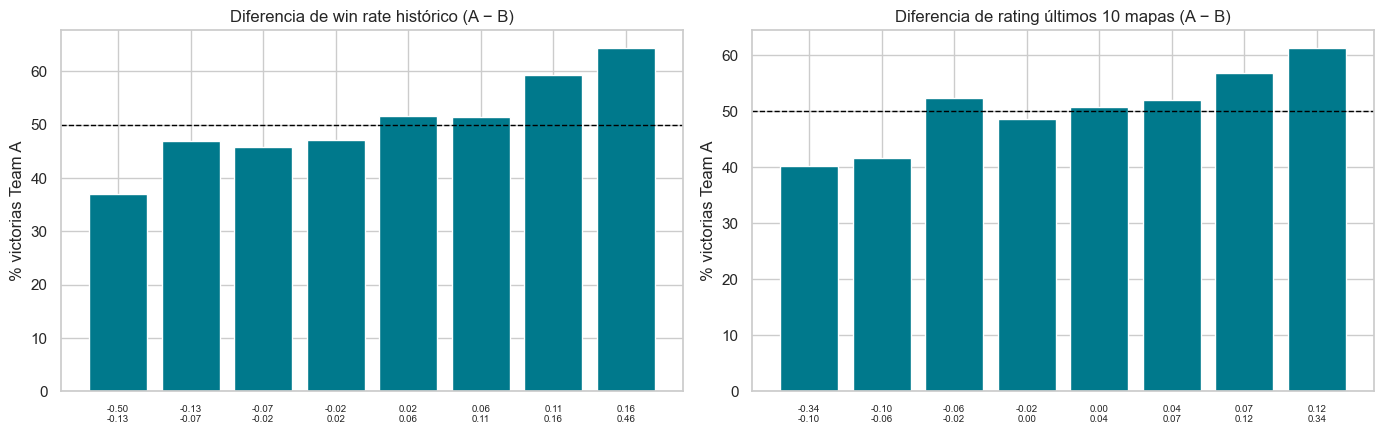

Correlación con team_a_wins -> wr_prev_diff: 0.160 | rating_prev_diff: 0.134
Accuracy regla 'gana el de mejor win rate histórico': 55.6%
Accuracy regla 'gana el de mejor rating reciente':     54.8%


In [14]:
# Pasar a formato largo: una fila por equipo-mapa, en orden cronológico
long = pd.concat([
    df[["match_id", "game_id", "team_a", "team_a_wins", "rating_a"]].rename(columns={"team_a": "team", "team_a_wins": "win", "rating_a": "rating"}),
    df[["match_id", "game_id", "team_b", "team_a_wins", "rating_b"]].assign(team_a_wins=lambda d: 1 - d["team_a_wins"])
      .rename(columns={"team_b": "team", "team_a_wins": "win", "rating_b": "rating"}),
]).sort_values(["match_id", "game_id"])

g = long.groupby("team")
long["maps_prev"] = g.cumcount()
long["wr_prev"] = g["win"].transform(lambda s: s.shift(1).expanding().mean())
long["rating_prev"] = g["rating"].transform(lambda s: s.shift(1).rolling(10, min_periods=3).mean())

# Volver a formato ancho (una fila por mapa)
feat_a = long.rename(columns={"team": "team_a", "maps_prev": "maps_prev_a", "wr_prev": "wr_prev_a", "rating_prev": "rating_prev_a"})
feat_b = long.rename(columns={"team": "team_b", "maps_prev": "maps_prev_b", "wr_prev": "wr_prev_b", "rating_prev": "rating_prev_b"})
pre = (df[["match_id", "game_id", "team_a", "team_b", "team_a_wins", "map_picked_by"]]
       .merge(feat_a[["match_id", "game_id", "team_a", "maps_prev_a", "wr_prev_a", "rating_prev_a"]], on=["match_id", "game_id", "team_a"])
       .merge(feat_b[["match_id", "game_id", "team_b", "maps_prev_b", "wr_prev_b", "rating_prev_b"]], on=["match_id", "game_id", "team_b"]))
pre["wr_prev_diff"] = pre["wr_prev_a"] - pre["wr_prev_b"]
pre["rating_prev_diff"] = pre["rating_prev_a"] - pre["rating_prev_b"]

# Solo mapas donde ambos equipos tienen historial suficiente
valid = pre[(pre["maps_prev_a"] >= 10) & (pre["maps_prev_b"] >= 10)].dropna(subset=["wr_prev_diff", "rating_prev_diff"])
print(f"Mapas con historial previo suficiente (>=10 mapas por equipo): {len(valid):,} de {len(df):,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, t in [(axes[0], "wr_prev_diff", "Diferencia de win rate histórico (A − B)"),
                   (axes[1], "rating_prev_diff", "Diferencia de rating últimos 10 mapas (A − B)")]:
    bins = pd.qcut(valid[col], 8, duplicates="drop")
    wr = valid.groupby(bins, observed=True)["team_a_wins"].agg(["mean", "count"])
    ax.bar(range(len(wr)), wr["mean"]*100, color="#00798c")
    ax.set_xticks(range(len(wr))); ax.set_xticklabels([f"{i.left:.2f}\n{i.right:.2f}" for i in wr.index], fontsize=7)
    ax.axhline(50, color="black", ls="--", lw=1); ax.set_title(t); ax.set_ylabel("% victorias Team A")
plt.tight_layout(); plt.show()

# Baseline "casino ingenuo": apostar al equipo con mejor historial
acc_wr = ((valid["wr_prev_diff"] > 0).astype(int) == valid["team_a_wins"])[valid["wr_prev_diff"] != 0].mean()
acc_rt = ((valid["rating_prev_diff"] > 0).astype(int) == valid["team_a_wins"]).mean()
print(f"Correlación con team_a_wins -> wr_prev_diff: {valid['wr_prev_diff'].corr(valid['team_a_wins']):.3f} | "
      f"rating_prev_diff: {valid['rating_prev_diff'].corr(valid['team_a_wins']):.3f}")
print(f"Accuracy regla 'gana el de mejor win rate histórico': {acc_wr*100:.1f}%")
print(f"Accuracy regla 'gana el de mejor rating reciente':     {acc_rt*100:.1f}%")

**Insight clave para el proyecto:** aun sin ver nada del mapa en cuestión, el **historial previo** de los equipos
ya tiene poder predictivo: la tasa de victoria de Team A crece de forma monótona con su ventaja histórica, y una
regla trivial ("apuesta al de mejor historial") acierta claramente más que el 50% de una moneda.

Ese número es nuestra **línea base**: cualquier modelo de ML que construyamos deberá superarla, y además
entregar probabilidades bien calibradas (no solo aciertos).

## 8. Conclusiones

### Hallazgos clave del EDA
1. **Variable objetivo balanceada** (50.3% / 49.7%): no se necesita re-muestreo y el *accuracy* es interpretable.
2. Las **diferencias de rendimiento** (rating, ACS, KAST, ADR) explican casi por completo quién gana un mapa, pero
   son *post-match* → **no se pueden usar directamente**; solo sus versiones históricas.
3. Existen *features* **pre-match legítimas con señal real**: quién eligió el mapa (+3–6 pts), historial de
   victorias y rating reciente (accuracy de regla simple > 50%), el mapa en sí (sesgo atacante/defensor, tasa de overtime).
4. Las **rondas pistola** y los **first kills** tienen un efecto desproporcionado sobre el resultado: son objetivos
   naturales para *features* históricas (¿qué tan bueno es el equipo en pistolas?).
5. Los **nulos** están concentrados y explicados (China, overtime, duración); los **outliers** son partidos reales
   (palizas y overtimes largos) y se conservan.
6. Alta **multicolinealidad** entre estadísticas de rendimiento → seleccionar o regularizar.